In [1]:

import pandas as pd
from pathlib import Path

# Locate project directory
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Load NASA data
fires = pd.read_csv(
    project_dir / "data/processed/fires_cleaned.csv"
)

# Load EPA data
pm25 = pd.read_csv(
    project_dir / "data/processed/pm25_cleaned.csv",
    dtype={
        "State Code": str,
        "County Code": str,
        "Site Num": str
    }
)

# Standardize dates
fires["acq_date"] = pd.to_datetime(
    fires["acq_date"]
)

pm25["Date Local"] = pd.to_datetime(
    pm25["Date Local"]
)

print("NASA fire detections:", len(fires))
print("EPA PM2.5 records:", len(pm25))

print("\nNASA columns:")
print(fires.columns.tolist())

print("\nEPA columns:")
print(pm25.columns.tolist())


NASA fire detections: 21694
EPA PM2.5 records: 8548

NASA columns:
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type', 'confidence_label']

EPA columns:
['State Code', 'County Code', 'Site Num', 'Parameter Code', 'POC', 'Latitude', 'Longitude', 'Datum', 'Parameter Name', 'Sample Duration', 'Pollutant Standard', 'Date Local', 'Units of Measure', 'Event Type', 'Observation Count', 'Observation Percent', 'Arithmetic Mean', '1st Max Value', '1st Max Hour', 'AQI', 'Method Code', 'Method Name', 'Local Site Name', 'Address', 'State Name', 'County Name', 'City Name', 'CBSA Name', 'Date of Last Change', 'method_priority']


In [2]:

print("NASA coordinates:")
display(
    fires[
        ["latitude", "longitude"]
    ].describe()
)

print("\nEPA coordinates:")
display(
    pm25[
        ["Latitude", "Longitude"]
    ].describe()
)

print("\nNASA date range:")
print(
    fires["acq_date"].min(),
    fires["acq_date"].max()
)

print("\nEPA date range:")
print(
    pm25["Date Local"].min(),
    pm25["Date Local"].max()
)


NASA coordinates:


,latitude,longitude
count,21694.000000,21694.000000
mean,37.384808,-120.484453
std,2.557796,1.839499
min,32.597510,-124.102710
25%,35.167873,-122.102038
50%,36.953000,-120.147820
75%,40.465985,-119.095577
max,41.926200,-114.623720



EPA coordinates:


,Latitude,Longitude
count,8548.000000,8548.000000
mean,36.126002,-119.530817
std,2.324449,1.960298
min,32.552824,-123.675233
25%,34.210169,-121.126371
50%,36.315670,-119.716433
75%,37.961578,-117.938450
max,41.726892,-115.483070



NASA date range:
2025-07-01 00:00:00 2025-09-30 00:00:00

EPA date range:
2025-07-01 00:00:00 2025-09-30 00:00:00


In [3]:

# Define columns identifying an EPA station
site_cols = [
    "State Code",
    "County Code",
    "Site Num"
]

# Extract unique monitoring station locations
stations = (
    pm25[
        site_cols + ["Latitude", "Longitude"]
    ]
    .drop_duplicates(subset=site_cols)
    .reset_index(drop=True)
)

# Create a station identifier
stations["station_id"] = (
    stations["State Code"].str.zfill(2)
    + "-"
    + stations["County Code"].str.zfill(3)
    + "-"
    + stations["Site Num"].str.zfill(4)
)

print("Unique stations:", len(stations))

display(stations.head())


Unique stations: 97


,State Code,County Code,Site Num,Latitude,Longitude,station_id
0,06,7,8,39.761680,-121.840470,06-007-0008
1,06,9,1,38.201850,-120.680277,06-009-0001
2,06,11,7,39.021221,-122.281803,06-011-0007
3,06,11,1002,39.189190,-121.998870,06-011-1002
4,06,19,11,36.785380,-119.773210,06-019-0011


In [4]:

import numpy as np
from sklearn.metrics.pairwise import haversine_distances

# Earth radius in kilometers
EARTH_RADIUS_KM = 6371.0088

# Convert coordinates from degrees to radians
station_coords = np.radians(
    stations[["Latitude", "Longitude"]].to_numpy()
)

fire_coords = np.radians(
    fires[["latitude", "longitude"]].to_numpy()
)

# Compute geographic distances
distance_matrix = (
    haversine_distances(
        station_coords,
        fire_coords
    ) * EARTH_RADIUS_KM
)

print("Distance matrix shape:", distance_matrix.shape)

print(
    "Minimum distance (km):",
    round(distance_matrix.min(), 2)
)

print(
    "Maximum distance (km):",
    round(distance_matrix.max(), 2)
)


Distance matrix shape: (97, 21694)
Minimum distance (km): 1.31
Maximum distance (km): 1224.68


In [5]:

# Count detections within geographic radii
stations["fires_within_50km"] = (
    (distance_matrix <= 50).sum(axis=1)
)

stations["fires_within_100km"] = (
    (distance_matrix <= 100).sum(axis=1)
)

# Calculate observed FRP within 100 km
frp_values = fires["frp"].to_numpy()

stations["frp_within_100km"] = (
    (distance_matrix <= 100) * frp_values
).sum(axis=1)

display(
    stations[
        [
            "station_id",
            "fires_within_50km",
            "fires_within_100km",
            "frp_within_100km"
        ]
    ].head(10)
)


,station_id,fires_within_50km,fires_within_100km,frp_within_100km
0,06-007-0008,274,544,6234.99
1,06-009-0001,315,710,21026.54
2,06-011-0007,518,1041,10010.40
3,06-011-1002,369,1023,10147.39
4,06-019-0011,81,5595,108551.41
5,06-019-0500,2025,5570,108341.60
6,06-019-2009,92,856,7586.80
7,06-019-2016,81,6211,115168.44
8,06-019-5001,109,5575,108386.35
9,06-019-5025,81,6038,113037.14


In [6]:

import pandas as pd

# NASA acquisition time is HHMM in UTC
fire_time = (
    fires["acq_time"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(4)
)

# Combine acquisition date and time
fire_datetime = pd.to_datetime(
    fires["acq_date"].dt.strftime("%Y-%m-%d")
    + " "
    + fire_time.str[:2]
    + ":"
    + fire_time.str[2:],
    errors="coerce",
    utc=True
)

# Convert UTC timestamps to California time
fires["datetime_local"] = (
    fire_datetime.dt.tz_convert(
        "America/Los_Angeles"
    )
)

fires["date_local"] = (
    fires["datetime_local"]
    .dt.tz_localize(None)
    .dt.normalize()
)

print("Missing timestamps:",
      fires["datetime_local"].isna().sum())

display(
    fires[
        [
            "acq_date",
            "acq_time",
            "datetime_local",
            "date_local"
        ]
    ].head()
)


Missing timestamps: 0


,acq_date,acq_time,datetime_local,date_local
0,2025-07-01,846,2025-07-01 01:46:00-07:00,2025-07-01
1,2025-07-01,846,2025-07-01 01:46:00-07:00,2025-07-01
2,2025-07-01,846,2025-07-01 01:46:00-07:00,2025-07-01
3,2025-07-01,846,2025-07-01 01:46:00-07:00,2025-07-01
4,2025-07-01,846,2025-07-01 01:46:00-07:00,2025-07-01


In [7]:

import numpy as np

# Daily dates in EPA dataset
study_dates = pd.date_range(
    "2025-07-01",
    "2025-09-30",
    freq="D"
)

# Fire detection dates
fire_dates = fires["date_local"].to_numpy(
    dtype="datetime64[ns]"
)

# Distance masks
near_50 = distance_matrix <= 50
near_100 = distance_matrix <= 100

# Fire Radiative Power
frp_values = fires["frp"].to_numpy()

daily_features = []

for date in study_dates:
    date_mask = fire_dates == np.datetime64(date)

    # Count detections on this day
    count_50 = near_50[:, date_mask].sum(axis=1)
    count_100 = near_100[:, date_mask].sum(axis=1)

    # Sum observed FRP within 100 km
    frp_100 = (
        near_100[:, date_mask]
        * frp_values[date_mask]
    ).sum(axis=1)

    daily_features.append(
        pd.DataFrame({
            "station_id": stations["station_id"],
            "date": date,
            "fire_count_50km": count_50,
            "fire_count_100km": count_100,
            "frp_sum_100km": frp_100
        })
    )

station_fire_daily = pd.concat(
    daily_features,
    ignore_index=True
)

print("Daily feature records:",
      len(station_fire_daily))

display(station_fire_daily.head(10))


Daily feature records: 8924


,station_id,date,fire_count_50km,fire_count_100km,frp_sum_100km
0,06-007-0008,2025-07-01,6,11,55.47
1,06-009-0001,2025-07-01,2,5,21.27
2,06-011-0007,2025-07-01,2,14,62.69
3,06-011-1002,2025-07-01,4,11,55.47
4,06-019-0011,2025-07-01,0,6,113.66
5,06-019-0500,2025-07-01,0,5,113.34
6,06-019-2009,2025-07-01,0,2,19.09
7,06-019-2016,2025-07-01,0,6,113.66
8,06-019-5001,2025-07-01,0,6,113.66
9,06-019-5025,2025-07-01,0,4,94.57


In [8]:

# Recreate station identifiers in EPA dataset
pm25["station_id"] = (
    pm25["State Code"].str.zfill(2)
    + "-"
    + pm25["County Code"].str.zfill(3)
    + "-"
    + pm25["Site Num"].str.zfill(4)
)

# Rename columns for consistency
pm25_model = pm25.rename(
    columns={
        "Date Local": "date",
        "Arithmetic Mean": "pm25"
    }
).copy()

# Merge by station and date
combined = pm25_model.merge(
    station_fire_daily,
    on=["station_id", "date"],
    how="left",
    validate="one_to_one"
)

print("Combined dataset rows:", len(combined))

print("\nMissing geographic features:")
print(
    combined[
        [
            "fire_count_50km",
            "fire_count_100km",
            "frp_sum_100km"
        ]
    ].isna().sum()
)

display(
    combined[
        [
            "station_id",
            "date",
            "pm25",
            "fire_count_50km",
            "fire_count_100km",
            "frp_sum_100km"
        ]
    ].head(10)
)


Combined dataset rows: 8548

Missing geographic features:
fire_count_50km     0
fire_count_100km    0
frp_sum_100km       0
dtype: int64


,station_id,date,pm25,fire_count_50km,fire_count_100km,frp_sum_100km
0,06-007-0008,2025-07-01,9.1,6,11,55.47
1,06-007-0008,2025-07-02,8.8,4,5,30.24
2,06-007-0008,2025-07-03,10.0,0,4,22.92
3,06-007-0008,2025-07-04,6.7,4,4,17.04
4,06-007-0008,2025-07-05,13.2,3,3,27.69
5,06-007-0008,2025-07-06,6.1,0,1,6.82
6,06-007-0008,2025-07-07,7.2,2,5,58.93
7,06-007-0008,2025-07-08,5.6,2,2,22.97
8,06-007-0008,2025-07-09,5.2,2,4,12.57
9,06-007-0008,2025-07-10,23.8,5,5,24.53


In [9]:

output_path = (
    project_dir /
    "data/processed/fire_pm25_combined.csv"
)

combined.to_csv(output_path, index=False)

print("Integrated dataset saved!")
print(output_path)


Integrated dataset saved!
/Users/sumanthkamath/Documents/VS Code /EcoSentinel/data/processed/fire_pm25_combined.csv


,pm25,fire_count_50km,fire_count_100km,frp_sum_100km
count,8548.000000,8548.000000,8548.000000,8548.000000
mean,7.296362,4.348386,20.373772,442.668620
std,8.160026,34.314437,83.487236,2623.888545
min,-2.300000,0.000000,0.000000,0.000000
25%,4.300000,0.000000,0.000000,0.000000
50%,6.400000,0.000000,3.000000,4.400000
75%,9.100000,2.000000,9.000000,24.620000
max,427.900000,1153.000000,1270.000000,43601.940000


Spearman correlation with PM2.5:
pm25                1.000000
fire_count_50km     0.160735
fire_count_100km    0.215596
frp_sum_100km       0.178430
Name: pm25, dtype: float64


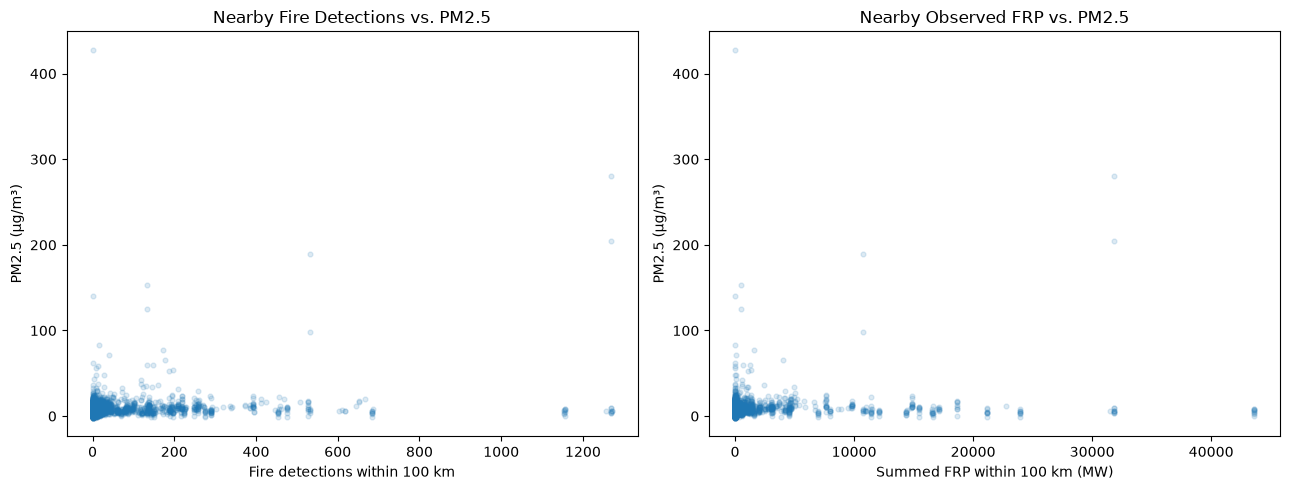

In [10]:

import matplotlib.pyplot as plt
import numpy as np

# View descriptive statistics
columns = [
    "pm25",
    "fire_count_50km",
    "fire_count_100km",
    "frp_sum_100km"
]

display(combined[columns].describe())

# Calculate Spearman correlations
correlations = (
    combined[columns]
    .corr(method="spearman")
)

print("Spearman correlation with PM2.5:")
print(correlations["pm25"])

# Visualize the relationships
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    combined["fire_count_100km"],
    combined["pm25"],
    alpha=0.15,
    s=12
)

axes[0].set_xlabel("Fire detections within 100 km")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_title("Nearby Fire Detections vs. PM2.5")

axes[1].scatter(
    combined["frp_sum_100km"],
    combined["pm25"],
    alpha=0.15,
    s=12
)

axes[1].set_xlabel("Summed FRP within 100 km (MW)")
axes[1].set_ylabel("PM2.5 (µg/m³)")
axes[1].set_title("Nearby Observed FRP vs. PM2.5")

plt.tight_layout()
plt.show()


In [11]:

# Inspect extreme PM2.5 observations
extreme_pm25 = combined.nlargest(15, "pm25")

columns = [
    "station_id",
    "date",
    "County Name",
    "pm25",
    "Event Type",
    "fire_count_50km",
    "fire_count_100km",
    "frp_sum_100km"
]

print("Top 15 PM2.5 observations:")
display(extreme_pm25[columns])

# Inspect negative readings
negative_pm25 = combined[
    combined["pm25"] < 0
]

print("\nNegative PM2.5 observations:",
      len(negative_pm25))

display(negative_pm25[columns])


Top 15 PM2.5 observations:


,station_id,date,County Name,pm25,Event Type,fire_count_50km,fire_count_100km,frp_sum_100km
2944,06-051-0005,2025-09-08,Mono,427.9,Included,0,0,0.00
1292,06-027-0002,2025-09-08,Inyo,280.5,Included,0,1268,31820.41
1596,06-027-1033,2025-09-08,Inyo,204.4,Included,0,1268,31820.41
1291,06-027-0002,2025-09-07,Inyo,189.8,Included,0,532,10763.57
1293,06-027-0002,2025-09-09,Inyo,153.6,Included,0,132,493.09
2943,06-051-0005,2025-09-07,Mono,139.9,Included,0,1,1.39
1597,06-027-1033,2025-09-09,Inyo,124.6,Included,0,132,493.09
1595,06-027-1033,2025-09-07,Inyo,98.3,Included,1,532,10763.57
2068,06-037-1103,2025-07-05,Los Angeles,83.3,NaN,7,15,11.79
7433,06-093-2001,2025-08-31,Siskiyou,77.4,Included,79,173,1589.60



Negative PM2.5 observations: 69


,station_id,date,County Name,pm25,Event Type,fire_count_50km,fire_count_100km,frp_sum_100km
195,06-011-0007,2025-07-23,Colusa,-0.2,Included,6,13,85.30
196,06-011-0007,2025-07-24,Colusa,-0.3,Included,0,7,109.73
199,06-011-0007,2025-07-27,Colusa,-0.1,Included,0,1,2.02
242,06-011-0007,2025-09-08,Colusa,-0.5,Included,7,12,82.00
243,06-011-0007,2025-09-09,Colusa,-0.5,Included,0,1,0.23
...,...,...,...,...,...,...,...,...
7151,06-087-0007,2025-08-17,Santa Cruz,-0.7,NaN,0,2,0.57
7239,06-087-1005,2025-08-16,Santa Cruz,-1.7,NaN,1,1,0.73
7262,06-087-1005,2025-09-08,Santa Cruz,-2.3,NaN,0,0,0.00
7263,06-087-1005,2025-09-09,Santa Cruz,-1.7,NaN,0,0,0.00


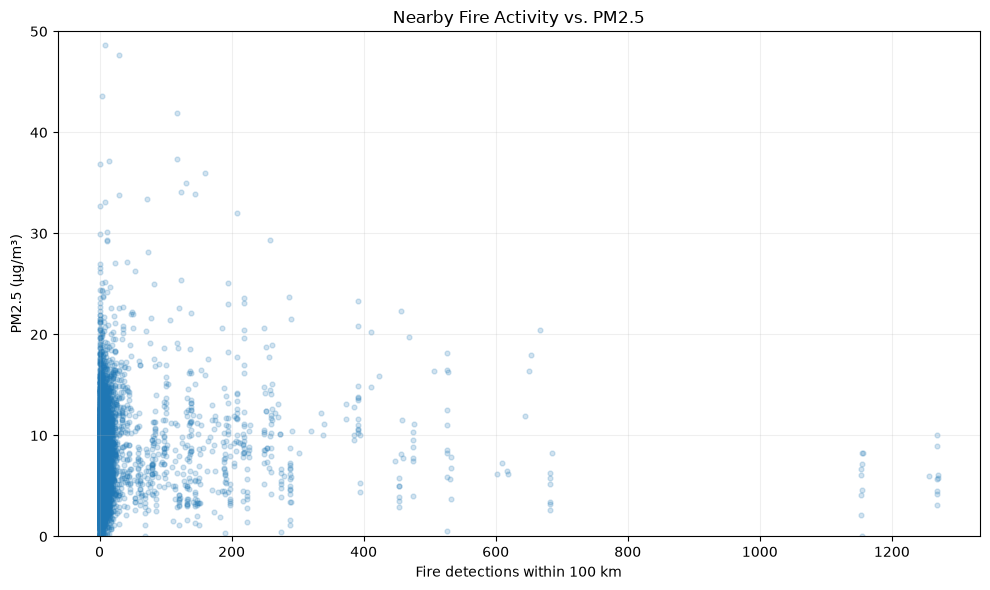

Observations displayed: 8460


In [12]:

import matplotlib.pyplot as plt

# Visualization subset only
plot_data = combined[
    combined["pm25"].between(0, 50)
].copy()

plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data["fire_count_100km"],
    plot_data["pm25"],
    alpha=0.2,
    s=12
)

plt.xlabel("Fire detections within 100 km")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Nearby Fire Activity vs. PM2.5")

plt.ylim(0, 50)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "Observations displayed:",
    len(plot_data)
)


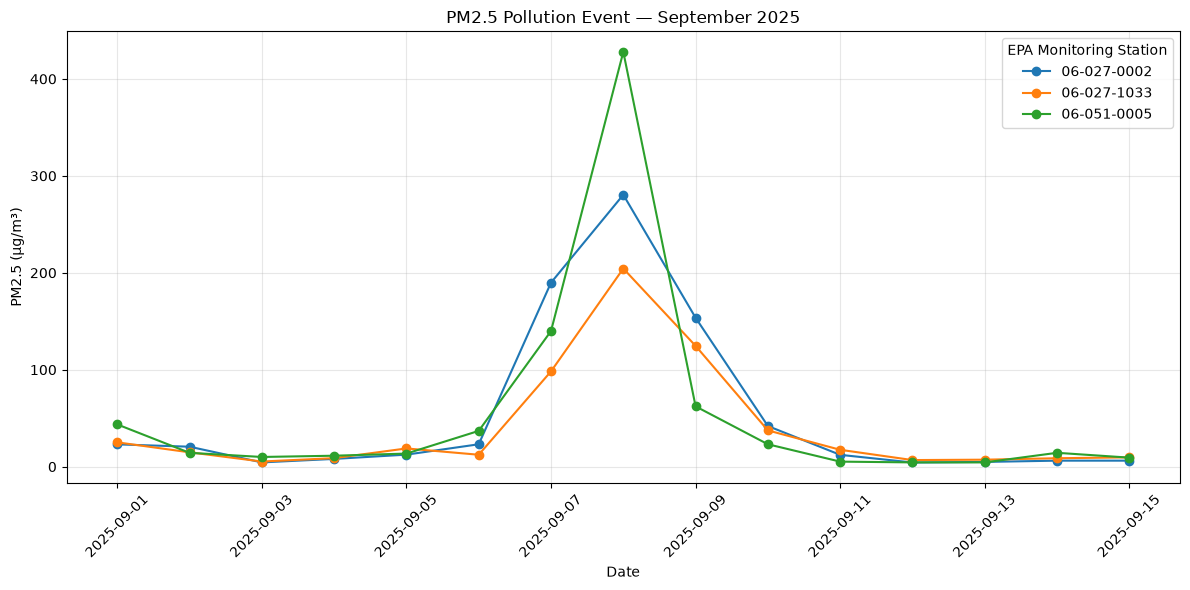

In [13]:

import matplotlib.pyplot as plt
import pandas as pd

# Monitoring stations of interest
selected_stations = [
    "06-051-0005",  # Mono County
    "06-027-0002",  # Inyo County
    "06-027-1033"   # Inyo County
]

# Study period around the extreme pollution event
event_data = combined[
    combined["station_id"].isin(selected_stations)
    & combined["date"].between(
        "2025-09-01", "2025-09-15"
    )
].copy()

plt.figure(figsize=(12, 6))

for station_id, group in event_data.groupby("station_id"):
    group = group.sort_values("date")
    plt.plot(
        group["date"],
        group["pm25"],
        marker="o",
        label=station_id
    )

plt.title("PM2.5 Pollution Event — September 2025")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend(title="EPA Monitoring Station")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [14]:

# Focus on the station with the highest PM2.5
mono = combined[
    (combined["station_id"] == "06-051-0005")
    & combined["date"].between(
        "2025-09-01", "2025-09-15"
    )
].copy()

display(
    mono[
        [
            "date",
            "pm25",
            "fire_count_50km",
            "fire_count_100km",
            "frp_sum_100km"
        ]
    ].sort_values("date")
)


,date,pm25,fire_count_50km,fire_count_100km,frp_sum_100km
2937,2025-09-01,43.6,0,4,42.80
2938,2025-09-02,14.3,0,1,1.06
2939,2025-09-03,10.0,0,0,0.00
2940,2025-09-04,11.3,0,0,0.00
2941,2025-09-05,13.5,0,1,0.65
2942,2025-09-06,36.9,0,1,3.48
2943,2025-09-07,139.9,0,1,1.39
2944,2025-09-08,427.9,0,0,0.00
2945,2025-09-09,62.2,0,0,0.00
2946,2025-09-10,23.1,1,1,0.58
